# [EDA] 고립 신호 후보 도출 — 2026-09-20

**작성자** — 김태은 (`taeeunni`)

> **본 지수는 방향성 외부검증 전 단계다.
> 동별·집단별 순위를 고립 위험도로 확정 해석하지 않는다.**

제공 데이터 안에는 "이 동이 실제로 고립 위험이 높다"를 확인할 정답이 없다.
따라서 이 노트북은 **후보 지표를 만들고 그 지표가 얼마나 불안정한지 보여주는 것**까지만 한다.

서울연구원(2023)의 4축 방법론을 우리 데이터로 재설계하되, 원본의 요인분석은 쓰지 않는다.
관측치가 동 47개뿐이라 요인분석 표본 요건(권장 100~200)을 충족하지 못한다.
대신 동등가중 합산 후 민감도·강건성·방향가정을 모두 검사한다.

In [1]:
import sys
import warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import loaders, paths, regions
from src.features import card_cohort, isolation, sk_dong
from src.visualization.style import PALETTE, SGG_COLORS, setup_style

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

FONT = setup_style()
print(f"한글 폰트: {FONT}")
print(f"pandas {pd.__version__} / numpy {np.__version__}")

한글 폰트: Malgun Gothic
pandas 3.0.6 / numpy 2.5.2


In [2]:
SEED = 42
panel = sk_dong.build_space_panel()
panel["지역"] = panel.dong_cd.str[:5].map(regions.SGG_NAMES)
card = card_cohort.prepare_card(2)
cohort = card_cohort.cohort_panel(card)
print(isolation.DISCLAIMER)
print()
print(f"공간축 {panel.dong_cd.nunique()}개 동 / 집단축 {len(cohort)}행")

본 지수는 방향성 외부검증 전 단계다. 동별·집단별 순위를 고립 위험도로 확정 해석하지 않는다.

공간축 47개 동 / 집단축 216행


## 1. 축 정의와 방향 가정

| 축 | 트랙 | 지표 | 방향 가정 | 가정의 근거와 약점 |
|---|---|---|---|---|
| 사회활동 | 공간 | `wkdy_cv` 요일간 변동계수 | 낮을수록 위험 | 요일 구분 없는 생활을 단조로움으로 봄. 단 농촌은 원래 요일차가 작다 |
| 사회활동 | 공간 | `time_entropy` 시간대 엔트로피 | 낮을수록 위험 | 활동 시간대 쏠림을 봄. 단 업무지구도 쏠린다 |
| 고립형 생활 | 공간 | `night_share` 야간(22~05시) 비중 | 낮을수록 위험 | 외출 없는 생활을 봄. 단 농촌은 원래 야간활동이 적다 |
| 고립형 생활 | 공간 | `peak_ratio` 평균/최대 | 낮을수록 위험 | 평탄하지 않은 활동을 봄. 해석이 가장 약하다 |
| 사회적 관계 | 집단 | `social_share` 대면 관계 업종 비중 | 낮을수록 위험 | 만나서 쓰는 돈이 적음 |
| 경제적 불안정 | 집단 | `amount_per_use` 건당 결제액 | 낮을수록 위험 | 소액 결제 위주 |
| 경제적 불안정 | 집단 | `ry_diversity` 이용 업종 수 | 낮을수록 위험 | 생활 반경이 좁음 |

**모든 방향 가정은 미검증이다.** 4절에서 방향을 뒤집었을 때 순위가 얼마나 바뀌는지 확인한다.

위 4개 공간축은 **후보**다. 2절에서 축 간 상관을 확인해 중복되는 축을 제거한 뒤
최종 축 집합을 확정한다.

## 2. 공간축 지표

In [3]:
SPACE_AXES_ALL = ["wkdy_cv", "time_entropy", "night_share", "peak_ratio"]
REDUNDANCY_THRESHOLD = 0.9

ind = isolation.space_indicators(panel)
ind["지역"] = ind.dong_cd.str[:5].map(regions.SGG_NAMES)
print("공간축 지표 기술통계")
print(ind[SPACE_AXES_ALL + ["senior_share", "total"]].describe().round(4).to_string())
print()
print("지역별 평균")
print(ind.groupby("지역")[SPACE_AXES_ALL + ["senior_share"]].mean().round(4).to_string())

공간축 지표 기술통계
       wkdy_cv  time_entropy  night_share  peak_ratio  senior_share         total
count   47.000        47.000       47.000      47.000        47.000        47.000
mean     0.112         2.953        0.093       0.558         0.247   196,368.174
std      0.062         0.037        0.018       0.032         0.068   217,359.066
min      0.022         2.866        0.055       0.496         0.142     4,596.988
25%      0.052         2.931        0.084       0.543         0.206    55,605.779
50%      0.107         2.956        0.094       0.556         0.247   122,884.975
75%      0.157         2.985        0.107       0.582         0.270   268,127.253
max      0.234         3.014        0.132       0.629         0.495 1,240,732.673

지역별 평균
        wkdy_cv  time_entropy  night_share  peak_ratio  senior_share
지역                                                                  
강원 춘천시    0.097         2.951        0.091       0.550         0.277
서울 강남구    0.128         2.955      

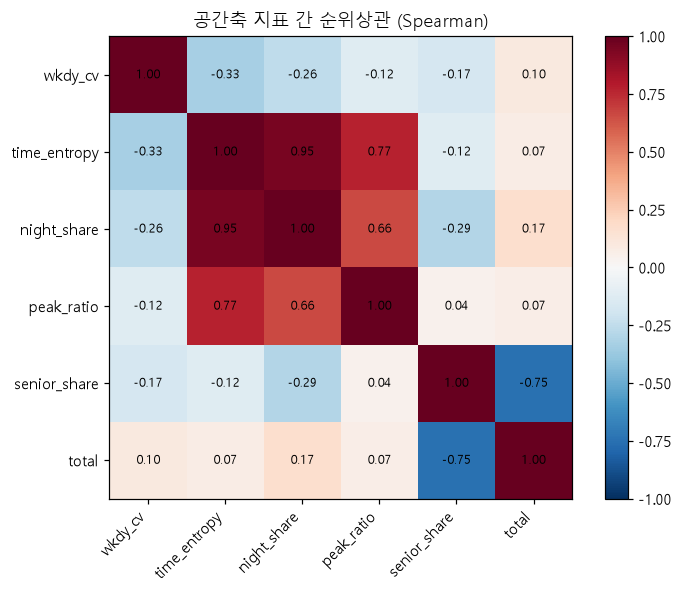

순위상관 절댓값 0.9 초과 축 쌍
  time_entropy <-> night_share: rho = 0.9514


In [4]:
corr = ind[SPACE_AXES_ALL + ["senior_share", "total"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.index)
ax.set_title("공간축 지표 간 순위상관 (Spearman)")
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

redundant = [(a, b, corr.loc[a, b]) for i, a in enumerate(SPACE_AXES_ALL)
             for b in SPACE_AXES_ALL[i + 1:]
             if abs(corr.loc[a, b]) > REDUNDANCY_THRESHOLD]
print(f"순위상관 절댓값 {REDUNDANCY_THRESHOLD} 초과 축 쌍")
for a, b, r in redundant:
    print(f"  {a} <-> {b}: rho = {r:.4f}")
if not redundant:
    print("  없음")

### 2.1 중복 축 제거

설계 규칙상 두 축의 상관이 0.9를 넘으면 같은 것을 두 번 세는 것이므로 하나를 뺀다.
제거 기준은 **해석 가능성**이다. `night_share`는 "야간에 나다니지 않는다"로 바로 읽히고
정책 언어로 옮기기 쉬운 반면 `time_entropy`는 추상적이다. 따라서 `time_entropy`를 뺀다.

어느 쪽을 빼든 결과가 같은지도 함께 확인한다.

In [5]:
DROPPED = "time_entropy"  # 중복쌍 중 해석 가능성이 낮은 쪽을 뺀다

SPACE_AXES = [c for c in SPACE_AXES_ALL if c != DROPPED] if redundant else list(SPACE_AXES_ALL)
print(f"제거된 축: {DROPPED if redundant else '없음'}")
print(f"최종 공간축: {SPACE_AXES}")
print()


def build_score(frame, axes, source):
    out = frame[["dong_cd"]].copy()
    for c in axes:
        out[c] = isolation.minmax(source[c], invert=True)
    out["score"] = isolation.composite(out, axes)
    return out


# 어느 쪽을 빼도 순위가 같은지 확인
alt_axes = [c for c in SPACE_AXES_ALL if c != "night_share"]
s_keep_night = build_score(ind, SPACE_AXES, ind).set_index("dong_cd").score
s_keep_entropy = build_score(ind, alt_axes, ind).set_index("dong_cd").score
s_all4 = build_score(ind, SPACE_AXES_ALL, ind).set_index("dong_cd").score

print("제거 선택에 따른 순위 비교 (Spearman)")
print(f"  time_entropy 제거 vs night_share 제거 : "
      f"{s_keep_night.corr(s_keep_entropy, method='spearman'):.4f}")
print(f"  time_entropy 제거 vs 4축 전부 사용    : "
      f"{s_keep_night.corr(s_all4, method='spearman'):.4f}")
print()
print("-> 값이 1에 가까우면 어느 쪽을 빼도 결론이 같다는 뜻이다")

제거된 축: time_entropy
최종 공간축: ['wkdy_cv', 'night_share', 'peak_ratio']

제거 선택에 따른 순위 비교 (Spearman)


  time_entropy 제거 vs night_share 제거 : 0.9831
  time_entropy 제거 vs 4축 전부 사용    : 0.9291

-> 값이 1에 가까우면 어느 쪽을 빼도 결론이 같다는 뜻이다


In [6]:
# 위험 방향으로 정규화 (모든 축 '낮을수록 위험' 가정 -> invert=True)
norm = ind[["dong_cd", "지역"]].copy()
for c in SPACE_AXES:
    norm[c] = isolation.minmax(ind[c], invert=True)
norm["score"] = isolation.composite(norm, SPACE_AXES)
norm["senior_share"] = ind.senior_share
norm["total"] = ind.total
norm = norm.sort_values("score", ascending=False).reset_index(drop=True)
norm.index = norm.index + 1

print("공간축 합성점수 상위 15개 행정동")
print(norm.head(15)[["dong_cd", "지역", "score"] + SPACE_AXES].round(3).to_string())
print()
print("하위 5개")
print(norm.tail(5)[["dong_cd", "지역", "score"]].round(3).to_string())
print()
print("지역별 점수 분포")
print(norm.groupby("지역").score.describe(percentiles=[0.5]).round(3).to_string())

공간축 합성점수 상위 15개 행정동
     dong_cd      지역  score  wkdy_cv  night_share  peak_ratio
1   32010110  강원 춘천시  0.835    0.901        0.815       0.789
2   32010390  강원 춘천시  0.812    0.511        0.946       0.980
3   11230580  서울 강남구  0.781    0.470        0.939       0.932
4   32010330  강원 춘천시  0.779    0.839        0.851       0.646
5   32010320  강원 춘천시  0.722    0.364        1.000       0.803
6   32010340  강원 춘천시  0.714    0.975        0.553       0.616
7   32010310  강원 춘천시  0.711    0.848        0.723       0.563
8   32010370  강원 춘천시  0.707    0.214        0.907       1.000
9   32010540  강원 춘천시  0.688    0.831        0.593       0.642
10  32010380  강원 춘천시  0.682    0.732        0.805       0.508
11  11230630  서울 강남구  0.676    0.682        0.476       0.869
12  11230600  서울 강남구  0.672    0.884        0.360       0.773
13  32010680  강원 춘천시  0.670    0.876        0.569       0.565
14  32010360  강원 춘천시  0.663    0.271        0.844       0.876
15  11230790  서울 강남구  0.662    0.531        0.628 

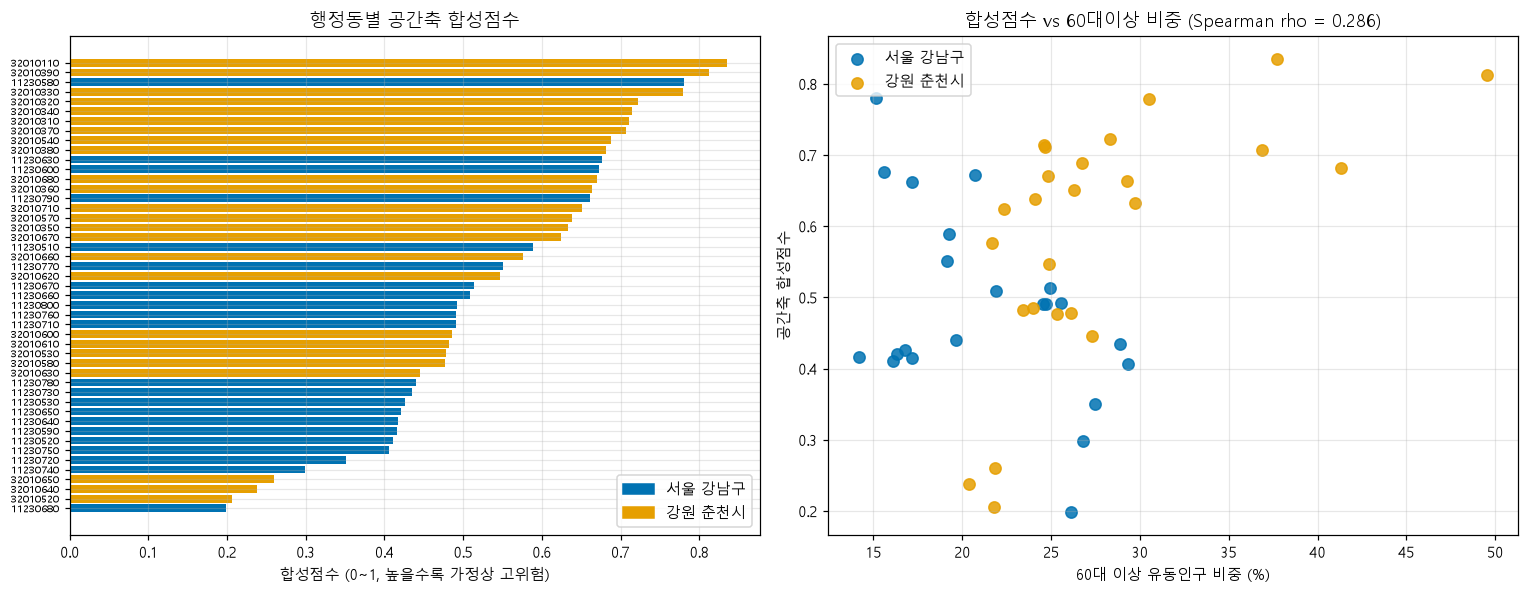

합성점수와 고령비중의 순위상관: 0.2856
고령비중은 지표에 넣지 않았으므로 이 상관은 독립적인 참고값이다


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ax = axes[0]
dd = norm.sort_values("score")
ax.barh(range(len(dd)), dd.score, color=[SGG_COLORS[z] for z in dd.지역])
ax.set_yticks(range(len(dd)))
ax.set_yticklabels(dd.dong_cd, fontsize=6.5)
ax.set_title("행정동별 공간축 합성점수")
ax.set_xlabel("합성점수 (0~1, 높을수록 가정상 고위험)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SGG_COLORS.values()]
ax.legend(handles, list(SGG_COLORS), loc="lower right")

ax = axes[1]
for z in SGG_COLORS:
    s = norm[norm.지역 == z]
    ax.scatter(s.senior_share * 100, s.score, s=55, color=SGG_COLORS[z], label=z, alpha=0.85)
rho = norm.score.corr(norm.senior_share, method="spearman")
ax.set_title(f"합성점수 vs 60대이상 비중 (Spearman rho = {rho:.3f})")
ax.set_xlabel("60대 이상 유동인구 비중 (%)")
ax.set_ylabel("공간축 합성점수")
ax.legend()
plt.tight_layout()
plt.show()
print(f"합성점수와 고령비중의 순위상관: {rho:.4f}")
print("고령비중은 지표에 넣지 않았으므로 이 상관은 독립적인 참고값이다")

## 3. 민감도 분석

가중치를 동등가중에서 ±20% 흔들어 200회 반복한다. 순위가 얼마나 흔들리는지 본다.

In [8]:
sens = isolation.sensitivity(norm, SPACE_AXES, n_trials=200, pct=0.2, seed=SEED)
sens = pd.concat([norm[["dong_cd", "지역", "score"]], sens], axis=1)
sens["순위폭"] = sens.rank_max - sens.rank_min
print("순위 변동 요약")
print(sens[["rank_std", "순위폭"]].describe().round(3).to_string())
print()
print("순위가 가장 많이 흔들린 동 10개")
print(sens.nlargest(10, "순위폭")[
    ["dong_cd", "지역", "score", "rank_mean", "rank_min", "rank_max", "순위폭"]
].round(2).to_string(index=False))

순위 변동 요약
       rank_std    순위폭
count    47.000 47.000
mean      1.261  5.234
std       0.831  3.564
min       0.000  0.000
25%       0.590  2.500
50%       1.240  5.000
75%       1.829  8.000
max       3.111 13.000

순위가 가장 많이 흔들린 동 10개
 dong_cd     지역  score  rank_mean  rank_min  rank_max    순위폭
11230640 서울 강남구  0.420     37.840    28.000    41.000 13.000
11230600 서울 강남구  0.670     12.090     7.000    18.000 11.000
32010360 강원 춘천시  0.660     13.640     7.000    18.000 11.000
32010350 강원 춘천시  0.630     17.570    11.000    22.000 11.000
32010610 강원 춘천시  0.480     29.360    25.000    36.000 11.000
32010370 강원 춘천시  0.710      8.060     5.000    15.000 10.000
11230710 서울 강남구  0.490     27.950    24.000    34.000 10.000
11230530 서울 강남구  0.430     35.470    29.000    39.000 10.000
11230760 서울 강남구  0.490     27.720    24.000    33.000  9.000
11230730 서울 강남구  0.430     36.060    32.000    41.000  9.000


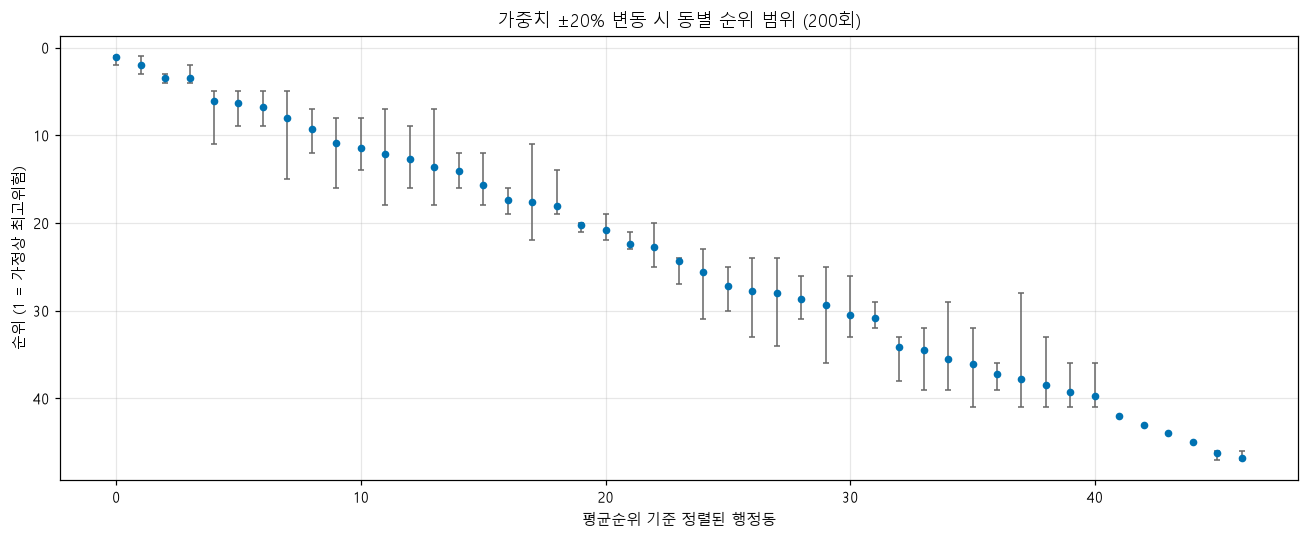

순위폭 중앙값 5.0위, 최대 13위 (전체 47개 중)
-> 순위폭이 크면 가중치 선택이 결론을 좌우한다는 뜻이다


In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
o = sens.sort_values("rank_mean")
ax.errorbar(range(len(o)), o.rank_mean,
            yerr=[o.rank_mean - o.rank_min, o.rank_max - o.rank_mean],
            fmt="o", ms=4, capsize=2, color=PALETTE[0], ecolor=PALETTE[7], lw=1)
ax.set_title("가중치 ±20% 변동 시 동별 순위 범위 (200회)")
ax.set_xlabel("평균순위 기준 정렬된 행정동")
ax.set_ylabel("순위 (1 = 가정상 최고위험)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()
print(f"순위폭 중앙값 {sens.순위폭.median():.1f}위, 최대 {sens.순위폭.max():.0f}위 (전체 47개 중)")
print("-> 순위폭이 크면 가중치 선택이 결론을 좌우한다는 뜻이다")

## 4. 방향 가정 민감도

모든 축의 방향 가정이 미검증이다. 축 하나씩 방향을 뒤집었을 때
원래 순위와 얼마나 달라지는지 확인한다. 이것이 이 지표의 가장 큰 취약점이다.

In [10]:
base_rank = norm.set_index("dong_cd").score.rank(ascending=False)
rows = []
for flip in SPACE_AXES:
    alt = ind[["dong_cd"]].copy()
    for c in SPACE_AXES:
        alt[c] = isolation.minmax(ind[c], invert=(c != flip))
    alt["score"] = isolation.composite(alt, SPACE_AXES)
    r = alt.set_index("dong_cd").score.rank(ascending=False)
    rows.append({
        "뒤집은 축": flip,
        "원래순위와 Spearman": base_rank.corr(r, method="spearman"),
        "상위10 유지수": len(set(base_rank.nsmallest(10).index) & set(r.nsmallest(10).index)),
    })
flip_df = pd.DataFrame(rows)
print("축 방향을 하나씩 뒤집었을 때 순위 변화")
print(flip_df.round(3).to_string(index=False))
print()
print("Spearman이 1에 가까우면 그 축은 결론에 영향이 작고,")
print("0이나 음수면 그 축의 방향 가정이 결론을 지배한다는 뜻이다.")

축 방향을 하나씩 뒤집었을 때 순위 변화
      뒤집은 축  원래순위와 Spearman  상위10 유지수
    wkdy_cv           0.338         4
night_share           0.429         3
 peak_ratio           0.352         5

Spearman이 1에 가까우면 그 축은 결론에 영향이 작고,
0이나 음수면 그 축의 방향 가정이 결론을 지배한다는 뜻이다.


## 5. 강건성 — 통(10자리) 단위 재현

분석 단위를 행정동(47개)에서 통급(148개)으로 바꿔도 같은 순위가 나오는지 확인한다.

통 단위 148개 -> 동 평균 47개
동 단위 점수 vs 통 평균 점수 Spearman rho = 0.8328

지역별
  서울 강남구: rho = 0.6589 (n=22)
  강원 춘천시: rho = 0.8762 (n=25)


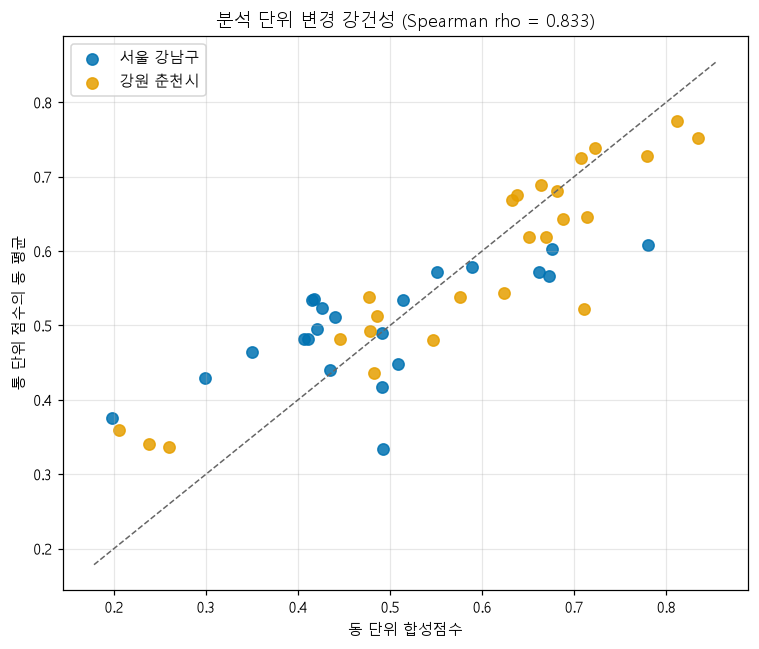

In [11]:
panel_t = sk_dong.build_space_panel(unit="tong_cd")
ind_t = isolation.space_indicators(panel_t)
norm_t = ind_t[["tong_cd"]].copy()
for c in SPACE_AXES:
    norm_t[c] = isolation.minmax(ind_t[c], invert=True)
norm_t["score"] = isolation.composite(norm_t, SPACE_AXES)
norm_t["dong_cd"] = norm_t.tong_cd.str[:8]

agg = norm_t.groupby("dong_cd").score.mean()
cmp = norm.set_index("dong_cd")[["score", "지역"]].join(agg.rename("score_tong"))
rho_t = cmp.score.corr(cmp.score_tong, method="spearman")
print(f"통 단위 {len(norm_t)}개 -> 동 평균 {len(agg)}개")
print(f"동 단위 점수 vs 통 평균 점수 Spearman rho = {rho_t:.4f}")
print()
print("지역별")
for z in SGG_COLORS:
    s = cmp[cmp.지역 == z]
    print(f"  {z}: rho = {s.score.corr(s.score_tong, method='spearman'):.4f} (n={len(s)})")

fig, ax = plt.subplots(figsize=(7, 6))
for z in SGG_COLORS:
    s = cmp[cmp.지역 == z]
    ax.scatter(s.score, s.score_tong, s=55, color=SGG_COLORS[z], label=z, alpha=0.85)
lim = [min(cmp.score.min(), cmp.score_tong.min()) - 0.02,
       max(cmp.score.max(), cmp.score_tong.max()) + 0.02]
ax.plot(lim, lim, "--", color=PALETTE[7], lw=1)
ax.set_title(f"분석 단위 변경 강건성 (Spearman rho = {rho_t:.3f})")
ax.set_xlabel("동 단위 합성점수")
ax.set_ylabel("통 단위 점수의 동 평균")
ax.legend()
plt.tight_layout()
plt.show()

## 6. 집단축 지표

카드는 시군구 2개뿐이므로 지역 × 성 × 연령의 36개 집단에서 산출한다.

In [12]:
COHORT_AXES = ["social_share", "amount_per_use", "ry_diversity"]
cind = isolation.cohort_indicators(cohort)
print("집단축 지표 기술통계")
print(cind[COHORT_AXES].describe().round(3).to_string())
print()
ccorr = cind[COHORT_AXES].corr(method="spearman")
print("축 간 순위상관")
print(ccorr.round(3).to_string())

집단축 지표 기술통계
       social_share  amount_per_use  ry_diversity
count        36.000          36.000        36.000
mean          0.209      34,099.314        77.250
std           0.089      12,908.409        13.683
min           0.100       8,177.349        29.000
25%           0.154      28,089.454        76.750
50%           0.183      38,020.756        82.000
75%           0.250      40,798.243        87.000
max           0.433      58,369.766        88.000

축 간 순위상관
                social_share  amount_per_use  ry_diversity
social_share           1.000          -0.609        -0.545
amount_per_use        -0.609           1.000        -0.041
ry_diversity          -0.545          -0.041         1.000


In [13]:
cnorm = cind[["MCT_SGG_CD", "SEX_CCD", "age_band"]].copy()
for c in COHORT_AXES:
    cnorm[c] = isolation.minmax(cind[c], invert=True)
cnorm["score"] = isolation.composite(cnorm, COHORT_AXES)
cnorm = cnorm.sort_values("score", ascending=False).reset_index(drop=True)
cnorm.index = cnorm.index + 1
print("집단축 합성점수 상위 12")
print(cnorm.head(12).round(3).to_string())
print()
print("하위 5")
print(cnorm.tail(5).round(3).to_string())

집단축 합성점수 상위 12
   MCT_SGG_CD SEX_CCD  age_band  social_share  amount_per_use  ry_diversity  score
1      강원 춘천시      여성        90         0.689           0.448         1.000  0.712
2      강원 춘천시      남성        90         0.709           0.128         0.847  0.562
3      서울 강남구      남성        10         0.439           0.972         0.186  0.533
4      강원 춘천시      여성        80         0.776           0.358         0.424  0.519
5      서울 강남구      여성        10         0.437           0.957         0.153  0.515
6      강원 춘천시      여성        10         0.037           0.979         0.475  0.497
7      강원 춘천시      남성        80         0.759           0.369         0.339  0.489
8      강원 춘천시      남성        10         0.000           1.000         0.458  0.486
9      서울 강남구      여성        40         1.000           0.419         0.017  0.479
10     서울 강남구      여성        30         0.834           0.571         0.017  0.474
11     서울 강남구      남성        30         0.811           0.589         0.

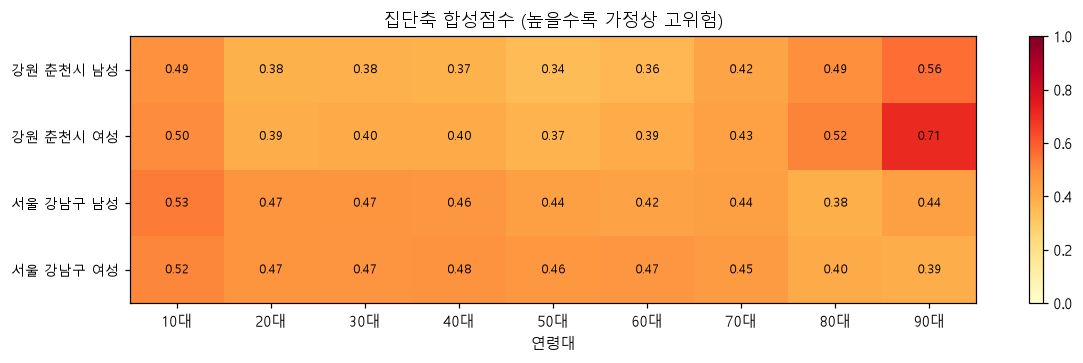

In [14]:
piv = cnorm.pivot_table(index=["MCT_SGG_CD", "SEX_CCD"], columns="age_band", values="score")
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(piv.values, cmap="YlOrRd", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(piv.columns)))
ax.set_xticklabels([f"{c}대" for c in piv.columns])
ax.set_yticks(range(len(piv.index)))
ax.set_yticklabels([f"{a} {b}" for a, b in piv.index], fontsize=9)
ax.set_title("집단축 합성점수 (높을수록 가정상 고위험)")
ax.set_xlabel("연령대")
ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [15]:
csens = isolation.sensitivity(cnorm, COHORT_AXES, n_trials=200, pct=0.2, seed=SEED)
csens = pd.concat([cnorm[["MCT_SGG_CD", "SEX_CCD", "age_band", "score"]], csens], axis=1)
csens["순위폭"] = csens.rank_max - csens.rank_min
print("집단축 순위 변동 요약 (가중치 ±20%, 200회)")
print(csens[["rank_std", "순위폭"]].describe().round(3).to_string())
print()
print("순위폭 상위 8")
print(csens.nlargest(8, "순위폭")[
    ["MCT_SGG_CD", "SEX_CCD", "age_band", "score", "rank_mean", "순위폭"]
].round(2).to_string(index=False))

집단축 순위 변동 요약 (가중치 ±20%, 200회)
       rank_std    순위폭
count    36.000 36.000
mean      2.219  9.000
std       1.475  5.652
min       0.000  0.000
25%       1.258  5.000
50%       1.845  9.000
75%       2.652 10.000
max       5.926 24.000

순위폭 상위 8
MCT_SGG_CD SEX_CCD  age_band  score  rank_mean    순위폭
    서울 강남구      남성        90  0.440     18.300 24.000
    강원 춘천시      남성        10  0.490     11.250 23.000
    강원 춘천시      여성        10  0.500      8.700 20.000
    강원 춘천시      여성        20  0.390     27.480 19.000
    강원 춘천시      남성        20  0.380     30.670 18.000
    서울 강남구      여성        90  0.390     28.230 14.000
    강원 춘천시      남성        80  0.490      7.700 11.000
    서울 강남구      남성        20  0.470     11.900 11.000


## 7. 시군구 수준 교차 대조

공간축과 집단축을 시군구 2개 수준에서 나란히 본다.
**n=2이므로 통계 검정이 아니라 방향 일치 여부만 본다.**

In [16]:
sp = norm.groupby("지역").score.mean()
co = cnorm.groupby("MCT_SGG_CD").score.mean()
cross = pd.DataFrame({"공간축 평균점수": sp, "집단축 평균점수": co})
cross["고령비중%"] = (norm.groupby("지역").senior_share.mean() * 100).round(2)
cross["절단근접도%"] = (
    card.groupby("MCT_SGG_CD").USE_CNT.apply(
        lambda s: (s <= card_cohort.NEAR_CUT_MAX).mean() * 100)
).round(2)
print(cross.round(4).to_string())
print()
print("n=2이므로 상관계수를 계산하지 않는다. 방향만 읽는다.")

        공간축 평균점수  집단축 평균점수  고령비중%  절단근접도%
강원 춘천시     0.589     0.439 27.740  37.440
서울 강남구     0.484     0.453 21.250  26.040

n=2이므로 상관계수를 계산하지 않는다. 방향만 읽는다.


## 7.5 외부 데이터 없이 가능한 타당도 검정

외부 검증이 답하는 것은 "이 지표가 고립을 재는가"(구성타당도) **하나**다.
그 앞에 내부 데이터만으로 확인할 수 있는 것들이 있고, 여기서 떨어지면
외부 검증을 해도 의미가 없다. 신뢰도 → 수렴타당도 → 음의 대조 → 기지집단 순으로 본다.

In [17]:
H1, H2 = ["202507", "202508", "202509"], ["202510", "202511", "202512"]


def score_for(months):
    sub = panel[panel.STD_YM.isin(months)]
    i = isolation.space_indicators(sub)
    n = i[["dong_cd"]].copy()
    for c in SPACE_AXES:
        n[c] = isolation.minmax(i[c], invert=True)
    n["score"] = isolation.composite(n, SPACE_AXES)
    return n.set_index("dong_cd").score, i.set_index("dong_cd")


s1, i1 = score_for(H1)
s2, i2 = score_for(H2)
print("[V1] 분할 신뢰도 — 전반기 vs 후반기")
print(f"  합성점수 Spearman = {s1.corr(s2, method='spearman'):.4f}")
print(f"  상위10 유지 {len(set(s1.nlargest(10).index) & set(s2.nlargest(10).index))}/10")
for c in SPACE_AXES + ["senior_share"]:
    print(f"    {c:14s} {i1[c].corr(i2[c], method='spearman'):.4f}")
print("  -> 0.9 이상이면 지표가 안정적으로 '무언가'를 재고 있다")

[V1] 분할 신뢰도 — 전반기 vs 후반기
  합성점수 Spearman = 0.9462
  상위10 유지 7/10
    wkdy_cv        0.9526
    night_share    0.9919
    peak_ratio     0.8892
    senior_share   0.9918
  -> 0.9 이상이면 지표가 안정적으로 '무언가'를 재고 있다


In [18]:
monthly = {ym: score_for([ym])[0] for ym in sorted(panel.STD_YM.unique())}
M = pd.DataFrame(monthly)
cm = M.corr(method="spearman")
tri = cm.to_numpy()[np.triu_indices(len(cm), 1)]
print("[V2] 월별 안정성 — 6개 월 상호 순위상관")
print(cm.round(3).to_string())
print(f"\n  평균 {tri.mean():.4f} / 최소 {tri.min():.4f}")

[V2] 월별 안정성 — 6개 월 상호 순위상관
        202507  202508  202509  202510  202511  202512
202507   1.000   0.987   0.946   0.911   0.919   0.937
202508   0.987   1.000   0.952   0.921   0.928   0.939
202509   0.946   0.952   1.000   0.886   0.932   0.913
202510   0.911   0.921   0.886   1.000   0.941   0.957
202511   0.919   0.928   0.932   0.941   1.000   0.953
202512   0.937   0.939   0.913   0.957   0.953   1.000

  평균 0.9348 / 최소 0.8861


In [19]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

prof = panel.groupby("dong_cd", observed=True)[sk_dong.TIME_COLS].sum()
Xc = StandardScaler().fit_transform(prof.div(prof.sum(axis=1), axis=0).values)
labc = KMeans(n_clusters=2, random_state=SEED, n_init=10).fit_predict(Xc)
members = set(prof.index[labc == np.bincount(labc).argmin()])

s_all = norm.set_index("dong_cd").score
top10 = set(s_all.nlargest(10).index)
inn, out = s_all[list(members)], s_all[[d for d in s_all.index if d not in members]]
diff = inn.mean() - out.mean()
rng = np.random.default_rng(SEED)
v = s_all.to_numpy()
null = [((p := rng.permutation(v))[:len(inn)].mean() - p[len(inn):].mean()) for _ in range(10000)]

print("[V3] 수렴 타당도 — 군집(독립 방법) vs 합성지수")
print(f"  상위10 교집합 {len(members & top10)}/10")
print(f"  소수군집 평균 {inn.mean():.4f} vs 나머지 {out.mean():.4f}  차이 {diff:.4f}")
print(f"  순열 10,000회 p = {(np.array(null) >= diff).mean():.4f}")

[V3] 수렴 타당도 — 군집(독립 방법) vs 합성지수
  상위10 교집합 7/10
  소수군집 평균 0.6964 vs 나머지 0.4974  차이 0.1990
  순열 10,000회 p = 0.0000


In [20]:
ind_all = isolation.space_indicators(panel).set_index("dong_cd")
chk = pd.DataFrame({"score": s_all, "총유동": ind_all.total, "고령비중": ind_all.senior_share})
chk["지역"] = [regions.SGG_NAMES[d[:5]] for d in chk.index]

print("[V4] 음의 대조 — 지표가 '동 크기'를 재고 있지 않은가")
print(f"  전체  총유동 {chk.score.corr(chk.총유동, method='spearman'):+.4f} / "
      f"고령비중 {chk.score.corr(chk.고령비중, method='spearman'):+.4f}")
for z, g in chk.groupby("지역"):
    print(f"  [{z}] 총유동 {g.score.corr(g.총유동, method='spearman'):+.4f} / "
          f"고령비중 {g.score.corr(g.고령비중, method='spearman'):+.4f}  (n={len(g)})")
print()
print("  ** 고령비중과의 부호가 지역별로 반대면 지표가 두 지역에서 다른 것을 재고 있다는 뜻 **")

[V4] 음의 대조 — 지표가 '동 크기'를 재고 있지 않은가
  전체  총유동 -0.2848 / 고령비중 +0.2856
  [강원 춘천시] 총유동 -0.3438 / 고령비중 +0.6631  (n=25)
  [서울 강남구] 총유동 +0.3642 / 고령비중 -0.3698  (n=22)

  ** 고령비중과의 부호가 지역별로 반대면 지표가 두 지역에서 다른 것을 재고 있다는 뜻 **


[V5] 기지집단 대조 — 업무지구/주거지에서 상식적 값이 나오는가
주말 유동 낙폭 상위 5 (업무지구 성격)
          주말낙폭%  score      지역
dong_cd                       
11230640 43.850  0.417  서울 강남구
32010520 41.720  0.206  강원 춘천시
11230590 40.770  0.416  서울 강남구
11230530 39.270  0.426  서울 강남구
11230720 37.670  0.351  서울 강남구

주말 유동 낙폭 하위 5 (주말에 오히려 증가)
           주말낙폭%  score      지역
dong_cd                        
32010370 -46.170  0.707  강원 춘천시
32010350 -43.340  0.633  강원 춘천시
32010360 -39.760  0.663  강원 춘천시
32010320 -32.460  0.722  강원 춘천시
32010390 -27.970  0.812  강원 춘천시

  주말낙폭 vs 합성점수 Spearman = -0.7586
  ** |r|이 크면 지표가 '고립'이 아니라 '업무지구 여부'를 재고 있다는 뜻 **


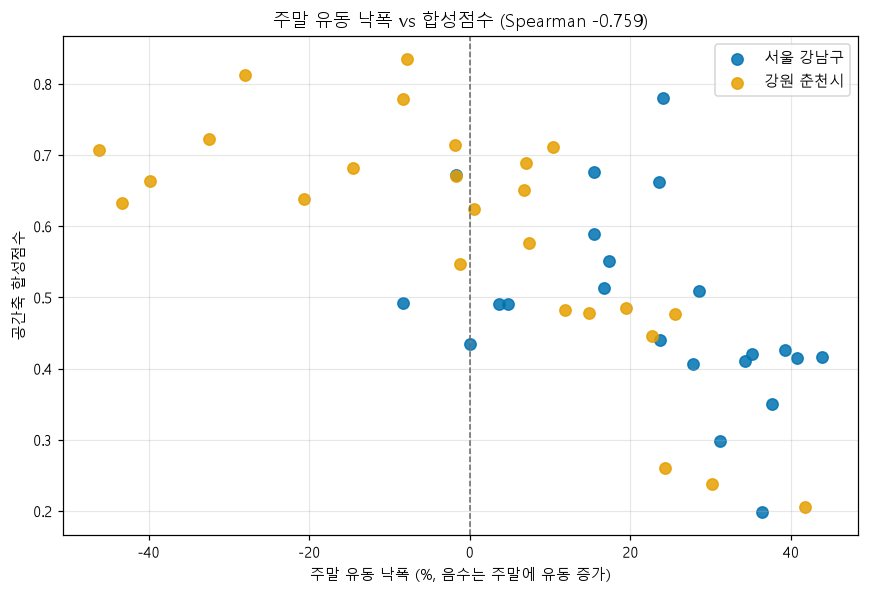

In [21]:
w = panel.groupby("dong_cd", observed=True)[sk_dong.WKDY_COLS].sum()
wk = w[[f"FLOW_POP_CNT_{d}" for d in ("MON", "TUS", "WED", "THU", "FRI")]].mean(axis=1)
we = w[["FLOW_POP_CNT_SAT", "FLOW_POP_CNT_SUN"]].mean(axis=1)
cmpx = pd.DataFrame({"주말낙폭%": ((1 - we / wk) * 100).round(2), "score": s_all})
cmpx["지역"] = [regions.SGG_NAMES[d[:5]] for d in cmpx.index]
r = cmpx["주말낙폭%"].corr(cmpx.score, method="spearman")

print("[V5] 기지집단 대조 — 업무지구/주거지에서 상식적 값이 나오는가")
print("주말 유동 낙폭 상위 5 (업무지구 성격)")
print(cmpx.nlargest(5, "주말낙폭%").round(3).to_string())
print("\n주말 유동 낙폭 하위 5 (주말에 오히려 증가)")
print(cmpx.nsmallest(5, "주말낙폭%").round(3).to_string())
print(f"\n  주말낙폭 vs 합성점수 Spearman = {r:+.4f}")
print("  ** |r|이 크면 지표가 '고립'이 아니라 '업무지구 여부'를 재고 있다는 뜻 **")

fig, ax = plt.subplots(figsize=(8, 5.5))
for z in SGG_COLORS:
    g = cmpx[cmpx.지역 == z]
    ax.scatter(g["주말낙폭%"], g.score, s=55, color=SGG_COLORS[z], label=z, alpha=0.85)
ax.axvline(0, color=PALETTE[7], lw=1, ls="--")
ax.set_title(f"주말 유동 낙폭 vs 합성점수 (Spearman {r:+.3f})")
ax.set_xlabel("주말 유동 낙폭 (%, 음수는 주말에 유동 증가)")
ax.set_ylabel("공간축 합성점수")
ax.legend()
plt.tight_layout()
plt.show()

### 7.5 판정

**신뢰도는 통과, 타당도에 적신호 두 개.**

| 검정 | 결과 | 판정 |
|---|---|---|
| V1 분할 신뢰도 | 0.946 | 통과 |
| V2 월별 안정성 | 평균 0.935 | 통과 |
| V3 수렴 타당도 | 교집합 7/10, p<0.0001 | 통과 |
| **V4 음의 대조** | **고령비중 부호가 춘천 +0.66 / 강남 −0.37로 반대** | **경고** |
| **V5 기지집단** | **주말낙폭과 −0.76** | **경고** |

지표는 **안정적으로 무언가를 재고 있다**(V1~V3). 그러나 그 무언가가 고립이라는 증거는 없고,
두 가지 반대 신호가 있다.

**V4** — 고령비중과의 관계 부호가 지역별로 뒤집힌다. 지표가 정말 고립을 잰다면
두 지역에서 최소한 부호는 같아야 한다. 강남 안에서는 고령이 많은 동이 오히려 저위험으로 나온다.

**V5** — 주말에 유동이 빠지는 동(업무지구)일수록 점수가 낮고, 주말에 유동이 느는 동일수록
점수가 높다. 상관이 −0.76으로 강하다. 변별력의 상당 부분이 **"업무지구인가 아닌가"**에 먹혔다.
춘천 면 지역은 주말에 유동이 20~46% *증가*하는데(수도권 근교 관광 유입으로 추정),
이 동들이 최상위를 차지한다.

→ **외부 검증 전에 축 재설계가 필요하다.** 외부 지표를 붙여도 현 상태로는
"업무지구 여부"와의 상관을 고립과의 상관으로 오독할 위험이 크다.

## 8. 한계

이 노트북 결과를 쓸 때 반드시 함께 밝혀야 하는 것들이다.

1. **방향성 미검증** — 4축 모두 "낮을수록 위험"이 가정이다. 외부 지표(1인가구·고령가구·
   기초생활수급자 비율)와 대조하기 전까지 순위를 고립 위험도로 읽을 수 없다.
   4절에서 축 하나만 뒤집어도 순위가 크게 바뀌는 것을 보였다.
2. **지역 효과와 고립 효과가 분리되지 않는다** — 춘천 면 지역이 상위에 오는 것이
   고립 때문인지 농촌이기 때문인지 이 데이터로는 구분할 수 없다.
3. **n=47** — 요인분석을 쓸 수 없어 가중치를 이론으로 정했다. 가중치 근거가 약하다.
4. **카드는 시군구 2개** — 공간축과 집단축을 곱할 수 없다. 교차는 정성적 대조에 그친다.
5. **비식별 컷 편향** — 1단계에서 확인했듯 고령·춘천·희소업종이 체계적으로 지워졌다.
   집단축 지표는 살아남은 셀만 반영하므로 실제보다 양호하게 나올 수 있다.
6. **`USE_CNT` 추가 가공** — 데이터2는 7~10, 14~15, 20~21이 아예 없다.
   건당 결제액은 최하단 구간에서 왜곡된다.
7. **`CLN_SGG_CD`는 시도 단위** — 강남의 지역민 비중은 산출 불가다.

## 핵심 발견

**0. 공간축 후보 4개 중 하나는 중복이었다.**
`time_entropy`와 `night_share`의 순위상관이 0.95로 사실상 같은 것을 두 번 세고 있었다.
해석이 쉬운 `night_share`를 남기고 `time_entropy`를 제거해 3축으로 확정했다.
어느 쪽을 제거하든 순위가 거의 같다는 것도 함께 확인했다.

**1. 공간축 합성점수는 가중치보다 방향 가정에 훨씬 민감하다.**
가중치를 ±20% 흔들어도 순위는 비교적 안정적이지만, 축 하나의 방향을 뒤집으면
상위 10개 구성이 크게 바뀐다. 따라서 다음 작업의 우선순위는 가중치 정교화가 아니라
**외부 데이터로 방향을 검증하는 것**이다.

**2. 분석 단위를 통급(148개)으로 바꾸면 순위가 부분적으로만 재현된다.**
전체 Spearman은 0.83이지만 지역별로 갈린다. 춘천은 0.88로 안정적인 반면
**강남은 0.66에 그친다.** 강남은 동 내부 이질성이 커서 집계 수준에 따라 순위가 바뀐다는 뜻이다.
강남 동별 순위는 춘천보다 신뢰도가 낮게 다뤄야 한다.

**3. 지표와 고령 비중의 순위상관은 0.29로 약하다.**
고령 비중은 지표 산출에 넣지 않은 독립 참고값이다. 방향이 반대는 아니지만
"고령이 많은 동이 곧 지표 상위"라고 말할 수 있는 수준은 아니다.
지표가 고령 외의 무언가를 재고 있거나, 방향 가정이 부분적으로 틀렸을 수 있다.
어느 쪽인지는 외부 검증 없이 판별할 수 없다.

**다음 단계**

1. 행정동 단위 1인가구·고령가구·기초생활수급자 비율 확보 후 방향성 검증
2. 검증 결과에 따라 축 재설계 또는 방향 수정
3. 그 뒤에 모델링·에이전트 설계로 진행